# Alert analysis - volume, hit rate and false-positive rate by rule

Reads the outputs of `python run.py` (`results/`). *Hit* = the alerted customer was injected with the typology the rule
targets. *Any suspicious* = the customer carries any injected typology. FP rate = 1 - any-suspicious rate.

In [1]:
import pandas as pd, matplotlib.pyplot as plt, json
base = pd.read_csv("../results/rule_summary_baseline.csv"); tuned = pd.read_csv("../results/rule_summary_tuned.csv")
alerts = pd.read_csv("../results/alerts.csv", parse_dates=["alert_date"]); meta = json.load(open("../results/metrics.json"))
print({k: meta[k] for k in ("rows", "customers", "suspicious_customers")}); print("baseline:", meta["baseline"]); print("tuned:", meta["tuned"])

{'rows': 518492, 'customers': 2000, 'suspicious_customers': 190}
baseline: {'alerts': 693, 'per_month': 57.8, 'precision': 0.532, 'any_suspicious_rate': 0.616, 'suspicious_customers_alerted': 175}
tuned: {'alerts': 470, 'per_month': 39.2, 'precision': 0.826, 'any_suspicious_rate': 0.898, 'suspicious_customers_alerted': 190}


## Alert volume per month by rule - baseline vs tuned

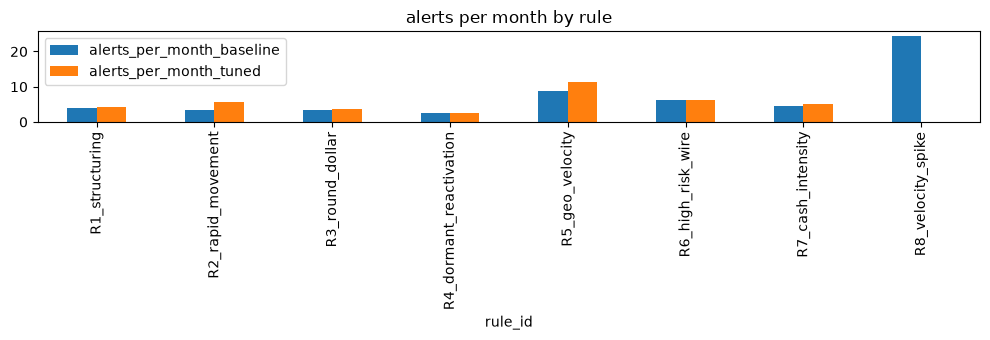

,alerts_per_month_baseline,alerts_per_month_tuned
rule_id,,
R1_structuring,4.1,4.3
R2_rapid_movement,3.5,5.8
R3_round_dollar,3.4,3.8
R4_dormant_reactivation,2.5,2.5
R5_geo_velocity,8.8,11.4
R6_high_risk_wire,6.3,6.3
R7_cash_intensity,4.6,5.1
R8_velocity_spike,24.5,NaN


In [2]:
cmp = base.set_index("rule_id")[["alerts_per_month"]].join(tuned.set_index("rule_id")[["alerts_per_month"]], lsuffix="_baseline", rsuffix="_tuned")
ax = cmp.plot(kind="bar", figsize=(10, 3.5), title="alerts per month by rule"); plt.tight_layout(); plt.show(); cmp

## Precision (hit rate) and false-positive rate by rule

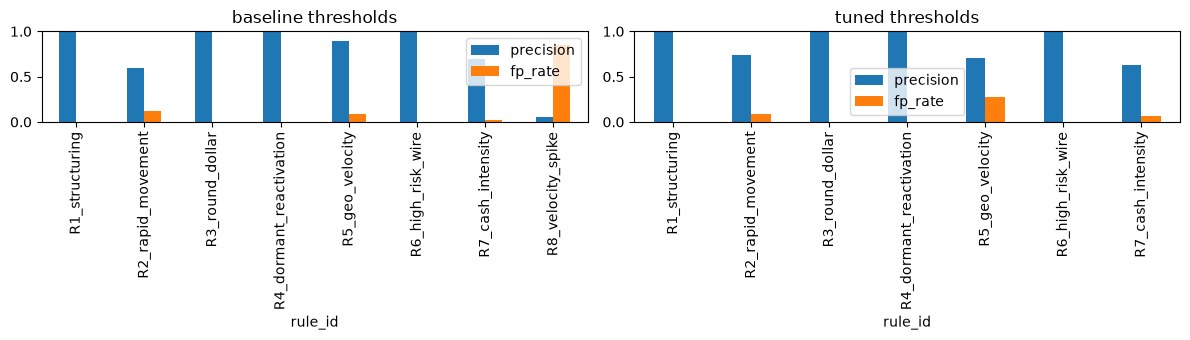

,rule_id,alerts,alerts_per_month,precision,fp_rate,recall,typology_customers,customers_caught
0,R1_structuring,52,4.3,1.000,0.000,1.000,40,40
1,R2_rapid_movement,69,5.8,0.739,0.087,1.000,35,35
2,R3_round_dollar,45,3.8,1.000,0.000,1.000,30,30
3,R4_dormant_reactivation,30,2.5,1.000,0.000,1.000,30,30
4,R5_geo_velocity,137,11.4,0.701,0.277,1.000,30,30
5,R6_high_risk_wire,76,6.3,1.000,0.000,1.000,25,25
6,R7_cash_intensity,61,5.1,0.623,0.066,0.925,40,37


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
base.set_index("rule_id")[["precision", "fp_rate"]].plot(kind="bar", ax=ax[0], title="baseline thresholds")
tuned.set_index("rule_id")[["precision", "fp_rate"]].plot(kind="bar", ax=ax[1], title="tuned thresholds")
for a in ax: a.set_ylim(0, 1)
plt.tight_layout(); plt.show()
tuned[["rule_id", "alerts", "alerts_per_month", "precision", "fp_rate", "recall", "typology_customers", "customers_caught"]]

## Recall of each injected typology (customers caught / customers injected)

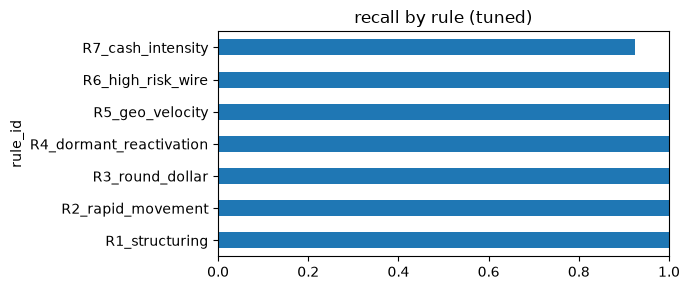

In [4]:
tuned.set_index("rule_id")["recall"].plot(kind="barh", figsize=(7, 3), xlim=(0, 1), title="recall by rule (tuned)"); plt.tight_layout(); plt.show()

## Alerts over time and priority mix

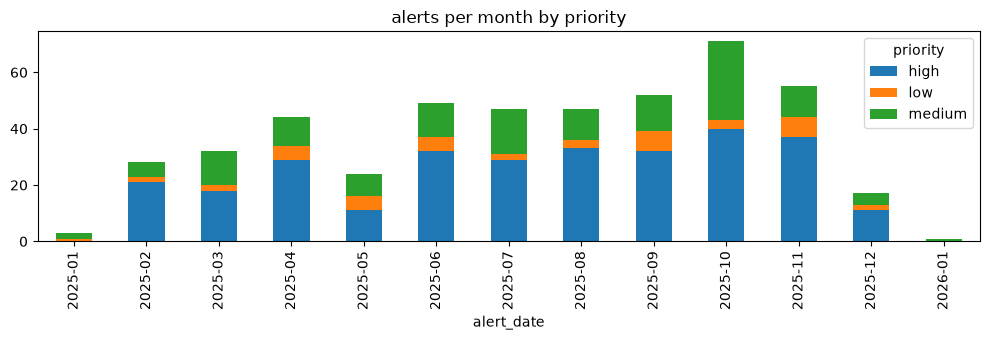

priority
high      293
medium    133
low        44
Name: count, dtype: int64

In [5]:
monthly = alerts.groupby([alerts.alert_date.dt.to_period("M"), "priority"]).size().unstack(fill_value=0)
monthly.plot(kind="bar", stacked=True, figsize=(10, 3.5), title="alerts per month by priority"); plt.tight_layout(); plt.show()
alerts.priority.value_counts()

## Threshold sweep - how alert volume and precision trade off per rule

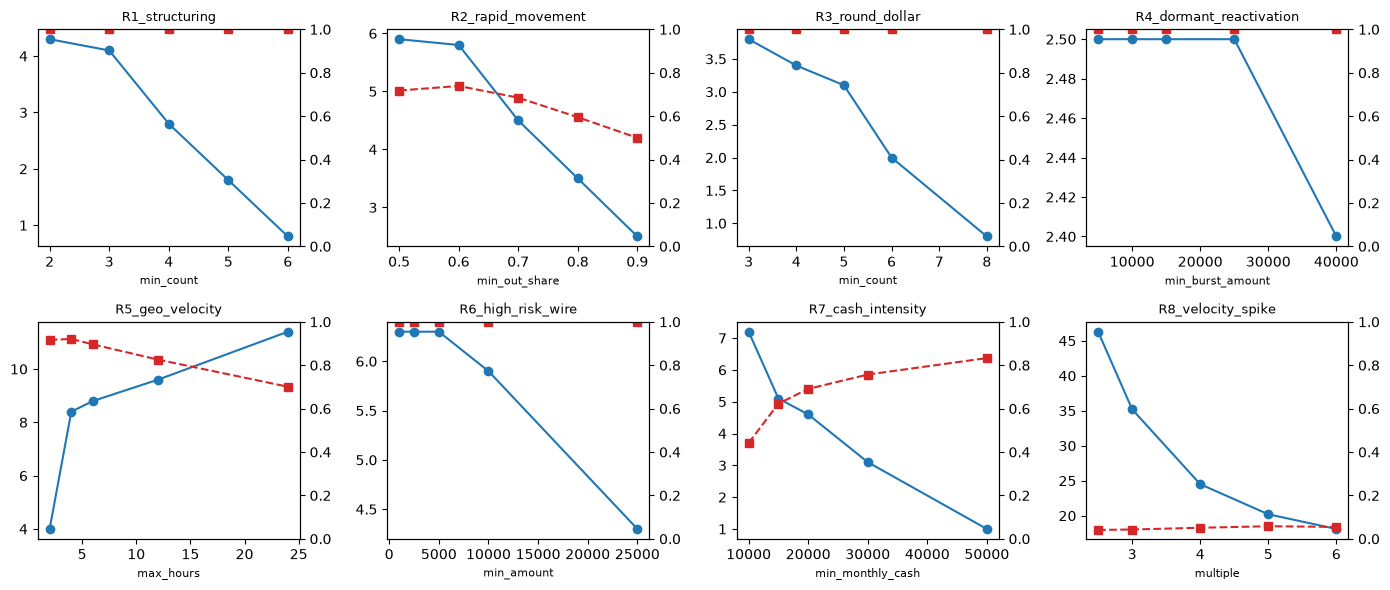

,rule_id,param,value,alerts_per_month,precision,recall,reason
0,R1_structuring,min_count,2.0,4.3,1.000,1.000,loosest setting above the precision floor (max...
1,R2_rapid_movement,min_out_share,0.6,5.8,0.739,1.000,tightened to fit analyst capacity
2,R3_round_dollar,min_count,3.0,3.8,1.000,1.000,loosest setting above the precision floor (max...
3,R4_dormant_reactivation,min_burst_amount,5000.0,2.5,1.000,1.000,loosest setting above the precision floor (max...
4,R5_geo_velocity,max_hours,24.0,11.4,0.701,1.000,loosest setting above the precision floor (max...
5,R6_high_risk_wire,min_amount,1000.0,6.3,1.000,1.000,loosest setting above the precision floor (max...
6,R7_cash_intensity,min_monthly_cash,15000.0,5.1,0.623,0.925,tightened to fit analyst capacity
7,R8_velocity_spike,multiple,6.0,0.0,0.055,0.200,never reaches precision 15% at any threshold -...


In [6]:
sweep = pd.read_csv("../results/tuning_sweep.csv")
fig, axes = plt.subplots(2, 4, figsize=(14, 6)); axes = axes.ravel()
for ax, (rule, g) in zip(axes, sweep.groupby("rule_id")):
    ax.plot(g.value, g.alerts_per_month, "o-", label="alerts/month"); ax.set_title(rule, fontsize=9); ax.set_xlabel(g.param.iloc[0], fontsize=8)
    ax2 = ax.twinx(); ax2.plot(g.value, g.precision, "s--", color="C3", label="precision"); ax2.set_ylim(0, 1)
plt.tight_layout(); plt.show()
pd.read_csv("../results/tuning_selection.csv")[["rule_id", "param", "value", "alerts_per_month", "precision", "recall", "reason"]]